In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, roc_curve

In [2]:
df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")
print(df.shape)
df.head()

(253680, 22)


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth               253680 non-null  float64
 15  MentHlth   

In [4]:
#DATA CLEANING
print("Missing values:", df.isnull().sum().sum())

print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

# BMI > 70 is not realistic
print("Rows with BMI > 70:", (df["BMI"] > 70).sum())
df = df[df["BMI"] <= 70]

df = df.astype(int)

# 0 = no diabetes, 1 = prediabetes or diabetes
df["Diabetes_binary"] = (df["Diabetes_012"] > 0).astype(int)

print("Shape after cleaning:", df.shape)

Missing values: 0


Duplicate rows: 23899
Rows with BMI > 70: 584


Shape after cleaning: (229197, 23)


In [5]:
#DESCRIPTIVE STATISTICS
df[["BMI", "MentHlth", "PhysHlth", "GenHlth", "Age", "Income"]].describe().round(2)

,BMI,MentHlth,PhysHlth,GenHlth,Age,Income
count,229197.00,229197.00,229197.00,229197.00,229197.00,229197.00
mean,28.55,3.51,4.68,2.60,8.09,5.89
std,6.26,7.71,9.05,1.06,3.09,2.09
min,12.00,0.00,0.00,1.00,1.00,1.00
25%,24.00,0.00,0.00,2.00,6.00,4.00
50%,27.00,0.00,0.00,3.00,8.00,6.00
75%,32.00,2.00,4.00,3.00,10.00,8.00
max,70.00,30.00,30.00,5.00,13.00,8.00


In [6]:
#SKEWNESS + LOG TRANSFORMATION
for col in ["BMI", "MentHlth", "PhysHlth"]:
    print(col, round(df[col].skew(), 2), "->", round(np.log1p(df[col]).skew(), 2))

BMI 1.19 -> 0.42
MentHlth 2.55 -> 1.38
PhysHlth 2.05 -> 1.1


In [7]:
#CLASS DISTRIBUTION
print(df["Diabetes_012"].value_counts())
print((df["Diabetes_012"].value_counts(normalize=True) * 100).round(1))

Diabetes_012
0    189559
2     35021
1      4617
Name: count, dtype: int64
Diabetes_012
0    82.7
2    15.3
1     2.0
Name: proportion, dtype: float64


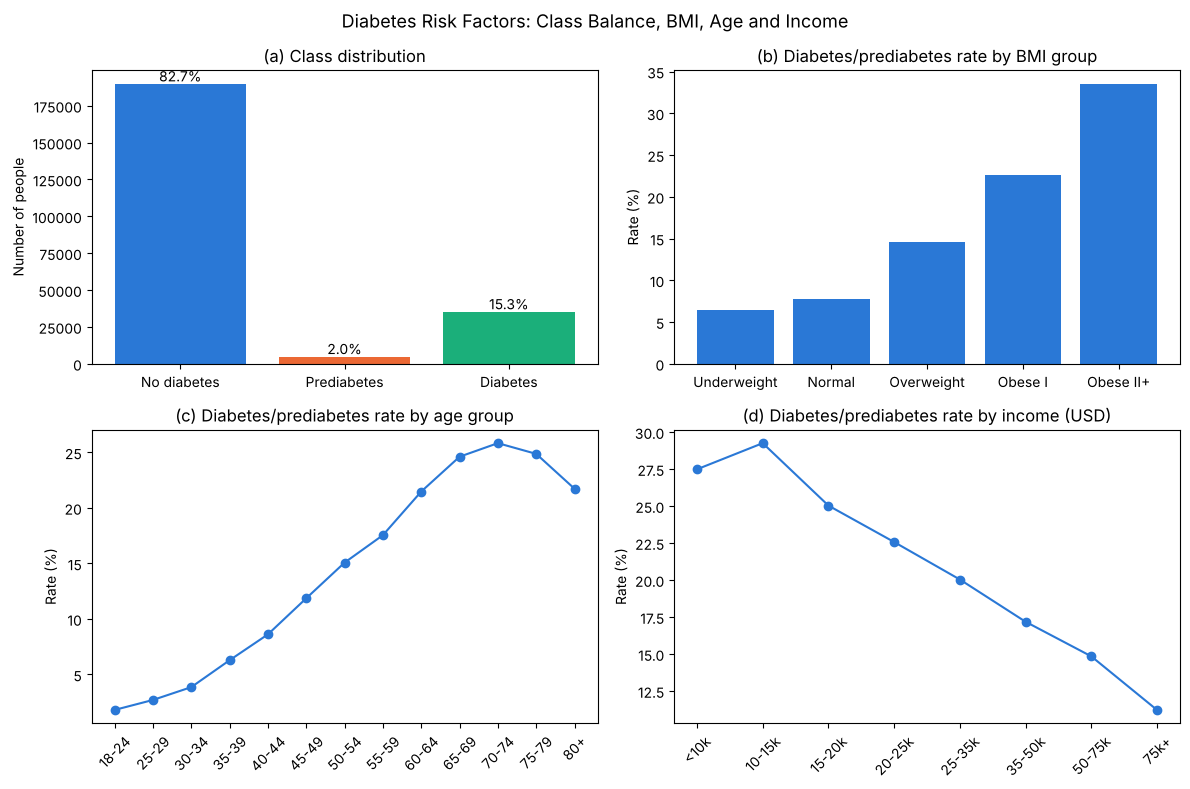

In [8]:
#RISK FACTOR GRAPHS (BMI, AGE, INCOME)
age_labels = ["18-24", "25-29", "30-34", "35-39", "40-44", "45-49", "50-54",
              "55-59", "60-64", "65-69", "70-74", "75-79", "80+"]
income_labels = ["<10k", "10-15k", "15-20k", "20-25k", "25-35k", "35-50k", "50-75k", "75k+"]
df["BMI_group"] = pd.cut(df["BMI"], bins=[0, 18.5, 25, 30, 35, 100], right=False,
                         labels=["Underweight", "Normal", "Overweight", "Obese I", "Obese II+"])

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

counts = df["Diabetes_012"].value_counts().sort_index()
bars = axes[0, 0].bar(["No diabetes", "Prediabetes", "Diabetes"], counts.values, color=["#2a78d6", "#eb6834", "#1baf7a"])
for b, v in zip(bars, counts.values):
    axes[0, 0].text(b.get_x() + b.get_width() / 2, v + 2000, f"{v / counts.sum():.1%}", ha="center")
axes[0, 0].set_title("(a) Class distribution")
axes[0, 0].set_ylabel("Number of people")

r = df.groupby("BMI_group", observed=True)["Diabetes_binary"].mean() * 100
axes[0, 1].bar(r.index.astype(str), r.values, color="#2a78d6")
axes[0, 1].set_title("(b) Diabetes/prediabetes rate by BMI group")
axes[0, 1].set_ylabel("Rate (%)")

r = df.groupby("Age")["Diabetes_binary"].mean() * 100
axes[1, 0].plot(age_labels, r.values, marker="o", color="#2a78d6")
axes[1, 0].set_title("(c) Diabetes/prediabetes rate by age group")
axes[1, 0].set_ylabel("Rate (%)")
axes[1, 0].tick_params(axis="x", rotation=45)

r = df.groupby("Income")["Diabetes_binary"].mean() * 100
axes[1, 1].plot(income_labels, r.values, marker="o", color="#2a78d6")
axes[1, 1].set_title("(d) Diabetes/prediabetes rate by income (USD)")
axes[1, 1].set_ylabel("Rate (%)")
axes[1, 1].tick_params(axis="x", rotation=45)

fig.suptitle("Diabetes Risk Factors: Class Balance, BMI, Age and Income", fontsize=13)
plt.tight_layout()
plt.savefig("fig_risk_factors.png", dpi=200)
plt.show()

In [9]:
print((df.groupby("BMI_group", observed=True)["Diabetes_binary"].mean() * 100).round(1))
print((df.groupby("Age")["Diabetes_binary"].mean() * 100).round(1))
print((df.groupby("Income")["Diabetes_binary"].mean() * 100).round(1))

BMI_group
Underweight     6.5
Normal          7.8
Overweight     14.6
Obese I        22.7
Obese II+      33.5
Name: Diabetes_binary, dtype: float64
Age
1      1.8
2      2.7
3      3.9
4      6.3
5      8.6
6     11.9
7     15.1
8     17.5
9     21.5
10    24.6
11    25.8
12    24.9
13    21.7
Name: Diabetes_binary, dtype: float64
Income
1    27.5
2    29.3
3    25.0
4    22.6
5    20.0
6    17.2
7    14.8
8    11.2
Name: Diabetes_binary, dtype: float64


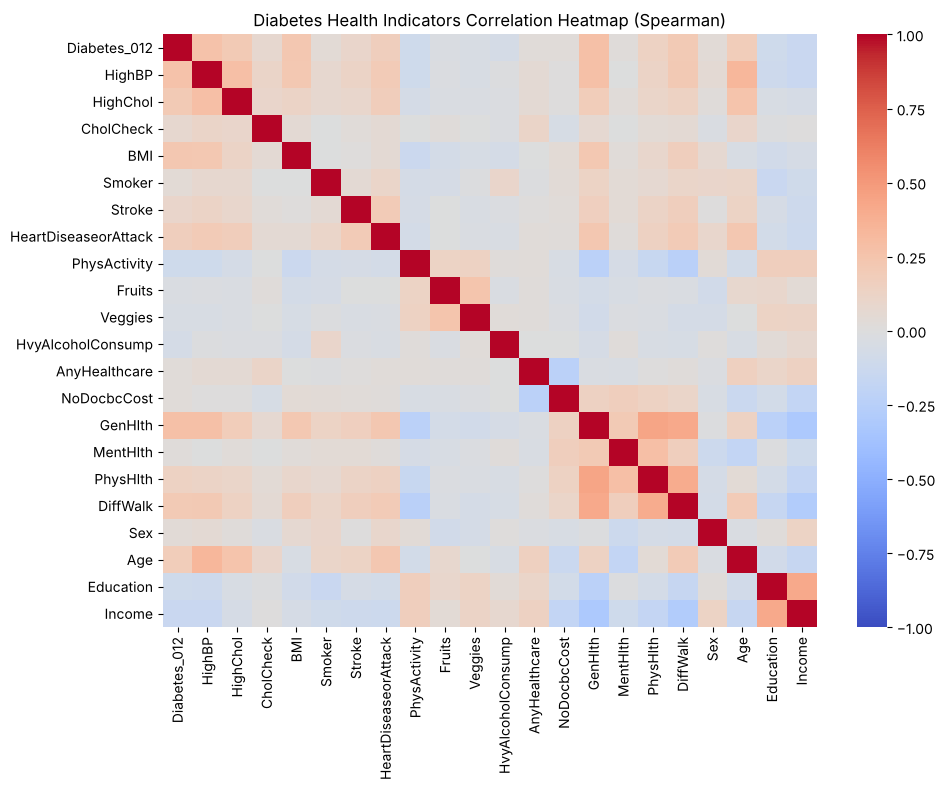

In [10]:
#CORRELATION HEATMAP (spearman because most columns are 0/1 or ordinal)
corr = df.drop(columns=["Diabetes_binary", "BMI_group"]).corr(method="spearman")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Diabetes Health Indicators Correlation Heatmap (Spearman)")
plt.tight_layout()
plt.savefig("fig_heatmap.png", dpi=200)
plt.show()

In [11]:
corr["Diabetes_012"].drop("Diabetes_012").sort_values(ascending=False).round(2)

GenHlth                 0.28
HighBP                  0.26
BMI                     0.23
DiffWalk                0.21
HighChol                0.20
Age                     0.18
HeartDiseaseorAttack    0.17
PhysHlth                0.14
Stroke                  0.10
CholCheck               0.08
Smoker                  0.05
Sex                     0.03
NoDocbcCost             0.02
AnyHealthcare           0.02
MentHlth                0.02
Fruits                 -0.03
Veggies                -0.04
HvyAlcoholConsump      -0.07
Education              -0.10
PhysActivity           -0.10
Income                 -0.15
Name: Diabetes_012, dtype: float64

In [12]:
#MULTICOLLINEARITY CHECK (threshold 0.85)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high = upper.stack()[upper.stack().abs() > 0.85]
print("Pairs with correlation > 0.85:", len(high))
print("Highest correlation:", upper.drop(index="Diabetes_012", columns="Diabetes_012").abs().max().max().round(2))

Pairs with correlation > 0.85: 0
Highest correlation: 0.44


In [13]:
df.drop(columns=["BMI_group"]).to_csv("diabetes_clean.csv", index=False)
print(df.drop(columns=["BMI_group"]).shape)

(229197, 23)


In [14]:
#BRFSS 2019, 2021, 2023 DATA CLEANING
years = {"2015": df.assign(Diabetes=(df["Diabetes_012"] == 2).astype(int))}
for y in ["2019", "2021", "2023"]:
    d = pd.read_csv(f"cdc_brfss_diabetes_{y}.csv")
    print(y, d.shape, "| duplicates:", d.duplicated().sum(), "| BMI > 70:", (d["BMI"] > 70).sum())
    d = d.drop_duplicates()
    d = d[d["BMI"] <= 70].astype(int).rename(columns={"Diabetes_binary": "Diabetes"})
    print("Shape after cleaning:", d.shape)
    years[y] = d

2019 (243317, 22) | duplicates: 19921 | BMI > 70: 97


Shape after cleaning: (223299, 22)


2021 (236378, 22) | duplicates: 13135 | BMI > 70: 124


Shape after cleaning: (223119, 22)


2023 (272769, 18) | duplicates: 33805 | BMI > 70: 139


Shape after cleaning: (238825, 18)


In [15]:
#DIABETES AND OBESITY RATE BY YEAR
for y, d in years.items():
    print(y, "diabetes: %.1f%%" % (100 * d["Diabetes"].mean()), "| obesity: %.1f%%" % (100 * (d["BMI"] >= 30).mean()))

2015 diabetes: 15.3% | obesity: 36.8%
2019 diabetes: 15.7% | obesity: 39.3%
2021 diabetes: 14.9% | obesity: 40.5%
2023 diabetes: 16.3% | obesity: 40.8%


In [16]:
#CORRELATION BY YEAR
common = [c for c in years["2023"].columns if c not in ["Diabetes", "Income", "Education"]]
corr_years = pd.DataFrame({y: d[common + ["Diabetes"]].corr(method="spearman")["Diabetes"].drop("Diabetes")
                           for y, d in years.items()}).sort_values("2015", ascending=False).round(2)
print(corr_years)
print(corr_years.corr().round(3))

                      2015  2019  2021  2023
GenHlth               0.27  0.27  0.26  0.24
HighBP                0.25  0.26  0.26  0.25
BMI                   0.22  0.20  0.19  0.18
DiffWalk              0.21  0.21  0.20  0.19
HighChol              0.19  0.20  0.19  0.19
Age                   0.18  0.19  0.19  0.20
HeartDiseaseorAttack  0.17  0.17  0.17  0.16
PhysHlth              0.14  0.14  0.13  0.11
Stroke                0.10  0.11  0.10  0.09
CholCheck             0.07  0.08  0.07  0.08
Smoker                0.05  0.04  0.05  0.04
Sex                   0.03  0.03  0.04  0.04
NoDocbcCost           0.02  0.01  0.01 -0.01
MentHlth              0.02  0.00 -0.01 -0.03
PhysActivity         -0.10 -0.11 -0.14 -0.13
       2015   2019   2021   2023
2015  1.000  0.996  0.992  0.983
2019  0.996  1.000  0.996  0.992
2021  0.992  0.996  1.000  0.995
2023  0.983  0.992  0.995  1.000


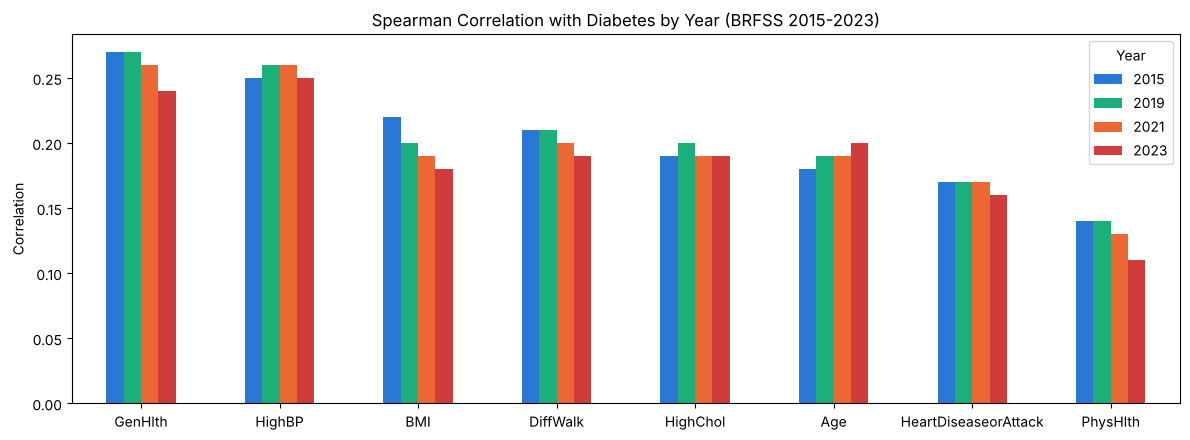

In [17]:
#CORRELATION BY YEAR GRAPH
top = corr_years.index[:8]
corr_years.loc[top].plot(kind="bar", figsize=(12, 4.5), color=["#2a78d6", "#1baf7a", "#eb6834", "#d03b3b"], rot=0)
plt.title("Spearman Correlation with Diabetes by Year (BRFSS 2015-2023)")
plt.ylabel("Correlation")
plt.legend(title="Year")
plt.tight_layout()
plt.savefig("fig_corr_years.png", dpi=200)
plt.show()

In [18]:
#NHANES 2021-2023
nh = pd.read_csv("nhanes_2021_2023.csv")
print(nh.shape)
nh.head()

(7723, 14)


,id,gender,age,poverty_ratio,bmi,waist_circ_cm,hba1c,diab_diag,prediab_diag,high_bp_diag,high_bp_meds,smk_100,pa_mod_min_wk,pa_vig_min_wk
0,130378.0,1.0,43.0,5.00,27.0,98.3,5.6,0.0,2.0,1.0,1.0,1.0,135.0,135.0
1,130379.0,1.0,66.0,5.00,33.5,114.7,5.6,0.0,2.0,1.0,1.0,1.0,180.0,135.0
2,130380.0,2.0,44.0,1.41,29.7,93.5,6.2,1.0,NaN,0.0,NaN,2.0,20.0,NaN
3,130384.0,1.0,43.0,0.63,NaN,NaN,NaN,0.0,2.0,0.0,NaN,2.0,NaN,NaN
4,130385.0,2.0,65.0,5.00,NaN,NaN,NaN,0.0,1.0,0.0,NaN,2.0,630.0,60.0


In [19]:
#NHANES DATA CLEANING
nh = nh[nh["hba1c"].notna()]
print("Adults with HbA1c:", len(nh))
print(nh.isnull().sum())

nh["male"] = (nh["gender"] == 1).astype(int)
nh["active_min_wk"] = nh["pa_mod_min_wk"].fillna(0) + nh["pa_vig_min_wk"].fillna(0)
nh["bp_med"] = (nh["high_bp_meds"] == 1).astype(int)
nh["told_prediabetes"] = (nh["prediab_diag"] == 1).astype(int)

Adults with HbA1c: 5703
id                  0
gender              0
age                 0
poverty_ratio     724
bmi                81
waist_circ_cm     258
hba1c               0
diab_diag           0
prediab_diag     1023
high_bp_diag        4
high_bp_meds     3534
smk_100             0
pa_mod_min_wk    1188
pa_vig_min_wk    3172
dtype: int64


In [20]:
#HbA1c GROUPS
nh["lab_group"] = pd.cut(nh["hba1c"], [0, 5.7, 6.5, 100], right=False, labels=["Normal", "Prediabetes", "Diabetes"])

def group(r):
    if r["diab_diag"] == 1:
        return "Diagnosed"
    if r["lab_group"] == "Diabetes":
        return "Undiagnosed"
    if r["lab_group"] == "Prediabetes":
        return "Prediabetes"
    return "Normal"

nh["group"] = nh.apply(group, axis=1)
print(pd.crosstab(nh["diab_diag"].map({1: "Told diabetes", 0: "Not told"}), nh["lab_group"], margins=True))
print((nh["group"].value_counts(normalize=True) * 100).round(1))

undiag = (nh["group"] == "Undiagnosed").sum()
all_diab = nh["group"].isin(["Diagnosed", "Undiagnosed"]).sum()
print("Undiagnosed / all diabetes: %.1f%%" % (100 * undiag / all_diab))
print("Prediabetes who were told: %.1f%%" % (100 * nh.loc[nh["group"] == "Prediabetes", "told_prediabetes"].mean()))

lab_group      Normal  Prediabetes  Diabetes   All
diab_diag                                         
Not told         3357         1383       152  4892
Told diabetes      65          183       563   811
All              3422         1566       715  5703
group
Normal         58.9
Prediabetes    24.3
Diagnosed      14.2
Undiagnosed     2.7
Name: proportion, dtype: float64
Undiagnosed / all diabetes: 15.8%
Prediabetes who were told: 26.3%


In [21]:
#GROUP MEANS
print(nh.groupby("group")[["age", "bmi", "waist_circ_cm", "hba1c"]].mean().round(1))

              age   bmi  waist_circ_cm  hba1c
group                                        
Diagnosed    63.2  33.1          110.9    7.5
Normal       49.1  28.4           97.0    5.3
Prediabetes  60.1  30.9          104.2    5.9
Undiagnosed  61.1  33.7          112.3    7.5


In [22]:
#UNDIAGNOSED RATE BY BMI
nd = nh[nh["diab_diag"] == 0].copy()
nd["undiag"] = (nd["lab_group"] == "Diabetes").astype(int)
nd["at_risk"] = nd["lab_group"].isin(["Prediabetes", "Diabetes"]).astype(int)
nd["BMI_group"] = pd.cut(nd["bmi"], [0, 25, 30, 35, 100], right=False, labels=["<25", "25-30", "30-35", "35+"])
bmi_rate = nd.groupby("BMI_group", observed=True)["undiag"].mean() * 100
print(bmi_rate.round(1))

BMI_group
<25      0.9
25-30    2.0
30-35    5.1
35+      6.5
Name: undiag, dtype: float64


In [23]:
#FINDRISC SCORE
def age_pts(a):
    return 0 if a < 45 else 2 if a < 55 else 3 if a < 65 else 4

def bmi_pts(b):
    return 0 if b < 25 else 1 if b <= 30 else 3

def waist_pts(w, male):
    if male == 1:
        return 0 if w < 94 else 3 if w <= 102 else 4
    return 0 if w < 80 else 3 if w <= 88 else 4

nd = nd.dropna(subset=["bmi", "waist_circ_cm"])
nd["age_p"] = nd["age"].apply(age_pts)
nd["bmi_p"] = nd["bmi"].apply(bmi_pts)
nd["waist_p"] = [waist_pts(w, m) for w, m in zip(nd["waist_circ_cm"], nd["male"])]
nd["active_p"] = np.where(nd["active_min_wk"] >= 210, 0, 2)
nd["bp_p"] = nd["bp_med"] * 2
nd["glucose_p"] = nd["told_prediabetes"] * 5
nd["findrisc"] = nd[["age_p", "bmi_p", "waist_p", "active_p", "bp_p", "glucose_p"]].sum(axis=1)
print("People:", len(nd))
print(nd.groupby("lab_group", observed=True)["findrisc"].mean().round(1))

People: 4686
lab_group
Normal          7.7
Prediabetes    11.2
Diabetes       12.7
Name: findrisc, dtype: float64


In [24]:
#FINDRISC AUC
print("AUC undiagnosed diabetes: %.3f" % roc_auc_score(nd["undiag"], nd["findrisc"]))
print("AUC prediabetes or diabetes: %.3f" % roc_auc_score(nd["at_risk"], nd["findrisc"]))
flag = nd["findrisc"] >= 12
print(f"FINDRISC >= 12: {flag.mean():.1%} flagged, {flag[nd['undiag'] == 1].mean():.1%} of undiagnosed diabetes found")

AUC undiagnosed diabetes: 0.752
AUC prediabetes or diabetes: 0.728
FINDRISC >= 12: 27.4% flagged, 61.1% of undiagnosed diabetes found


In [25]:
#SHORT QUESTIONNAIRE
scores = {"FINDRISC (6 questions)": nd["findrisc"],
          "4 questions": nd[["age_p", "bmi_p", "waist_p", "bp_p"]].sum(axis=1),
          "3 questions": nd[["age_p", "bmi_p", "waist_p"]].sum(axis=1)}
auc = {k: roc_auc_score(nd["undiag"], v) for k, v in scores.items()}
print(pd.Series(auc).round(3))

FINDRISC (6 questions)    0.752
4 questions               0.733
3 questions               0.732
dtype: float64


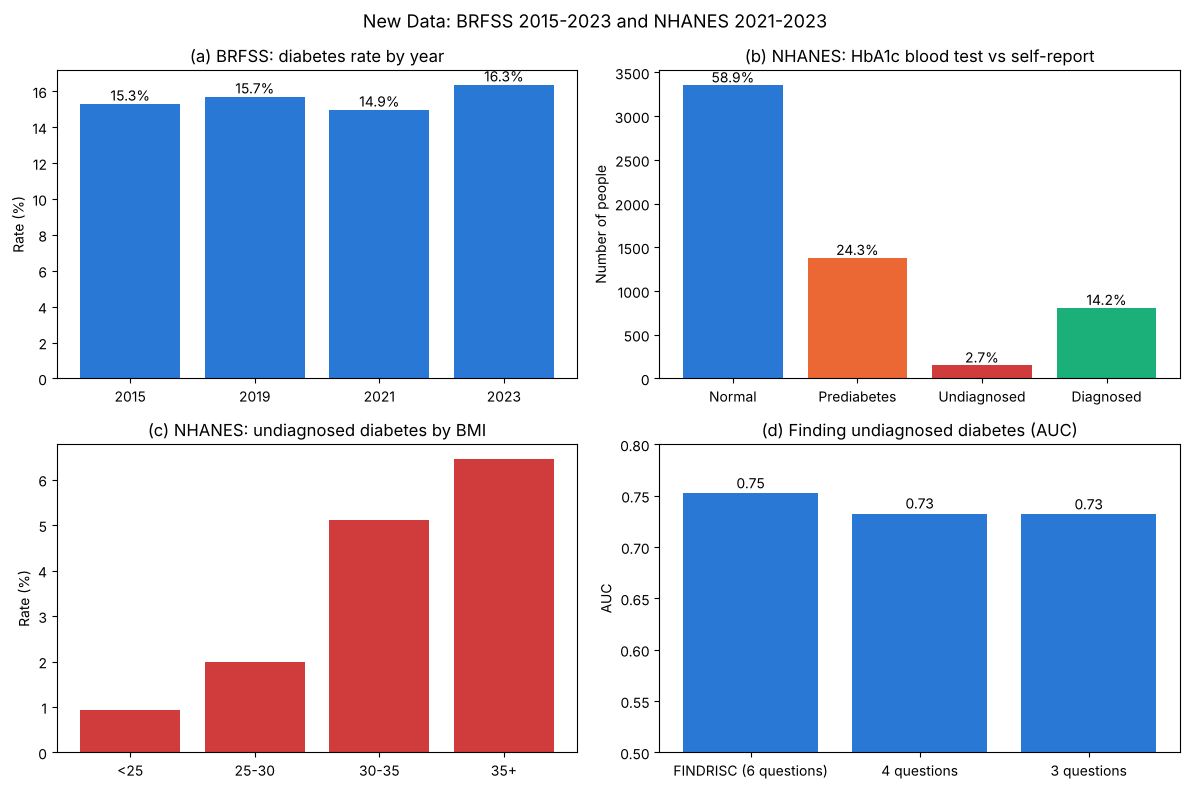

In [26]:
#NEW DATA GRAPHS
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

rates = [100 * d["Diabetes"].mean() for d in years.values()]
bars = axes[0, 0].bar(list(years), rates, color="#2a78d6")
for b, v in zip(bars, rates):
    axes[0, 0].text(b.get_x() + b.get_width() / 2, v + 0.2, f"{v:.1f}%", ha="center")
axes[0, 0].set_title("(a) BRFSS: diabetes rate by year")
axes[0, 0].set_ylabel("Rate (%)")

counts = nh["group"].value_counts().reindex(["Normal", "Prediabetes", "Undiagnosed", "Diagnosed"])
bars = axes[0, 1].bar(counts.index, counts.values, color=["#2a78d6", "#eb6834", "#d03b3b", "#1baf7a"])
for b, v in zip(bars, counts.values):
    axes[0, 1].text(b.get_x() + b.get_width() / 2, v + 30, f"{v / counts.sum():.1%}", ha="center")
axes[0, 1].set_title("(b) NHANES: HbA1c blood test vs self-report")
axes[0, 1].set_ylabel("Number of people")

axes[1, 0].bar(bmi_rate.index.astype(str), bmi_rate.values, color="#d03b3b")
axes[1, 0].set_title("(c) NHANES: undiagnosed diabetes by BMI")
axes[1, 0].set_ylabel("Rate (%)")

bars = axes[1, 1].bar(list(auc), list(auc.values()), color="#2a78d6")
for b, v in zip(bars, auc.values()):
    axes[1, 1].text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.2f}", ha="center")
axes[1, 1].set_ylim(0.5, 0.8)
axes[1, 1].set_title("(d) Finding undiagnosed diabetes (AUC)")
axes[1, 1].set_ylabel("AUC")

fig.suptitle("New Data: BRFSS 2015-2023 and NHANES 2021-2023", fontsize=13)
plt.tight_layout()
plt.savefig("fig_new_data.png", dpi=200)
plt.show()

In [27]:
#COMPARISON TABLE
tab = pd.DataFrame({
    "BRFSS 2023": [(years["2023"]["BMI"] >= 30).mean() * 100, years["2023"]["Diabetes"].mean() * 100,
                   years["2023"]["HighBP"].mean() * 100],
    "NHANES 2021-2023": [(nh["bmi"] >= 30).mean() * 100, ((nh["diab_diag"] == 1) | (nh["hba1c"] >= 6.5)).mean() * 100,
                         (nh["high_bp_diag"] == 1).mean() * 100]},
    index=["Obesity", "Diabetes", "High blood pressure"])
tr = pd.read_csv("turkiye_saglik_ozet.csv")
print(tr.shape)
print(tr[tr["sex"] == "Total"][["source", "indicator", "value", "measure"]])
sel = tr[(tr["sex"] == "Total") & tr["indicator"].isin(tab.index) & tr["source"].isin(["TUIK 2025", "WHO STEPS 2017"])]
tab = tab.join(sel.pivot(index="indicator", columns="source", values="value")).round(1)
tab

(51, 8)
            source                       indicator  value  \
0        TUIK 2022                         Obesity   20.2   
5        TUIK 2022                        Diabetes   11.4   
6        TUIK 2022             High blood pressure   16.1   
7        TUIK 2022                   Daily smoking   28.3   
12       TUIK 2025                         Obesity   21.8   
17       TUIK 2025                        Diabetes   11.9   
18       TUIK 2025             High blood pressure   16.9   
19       TUIK 2025                   Daily smoking   30.1   
24  WHO STEPS 2017  Insufficient physical activity   43.6   
27  WHO STEPS 2017          Overweight (BMI >= 25)   64.4   
30  WHO STEPS 2017                         Obesity   28.8   
33  WHO STEPS 2017             High blood pressure   27.7   
36  WHO STEPS 2017          Raised fasting glucose   11.1   
39  WHO STEPS 2017                        Diabetes   13.3   
42  WHO STEPS 2017      Impaired fasting glycaemia    7.9   
45  WHO STEPS 20

,BRFSS 2023,NHANES 2021-2023,TUIK 2025,WHO STEPS 2017
Obesity,40.8,40.5,21.8,28.8
Diabetes,16.3,16.9,11.9,13.3
High blood pressure,45.2,38.1,16.9,27.7


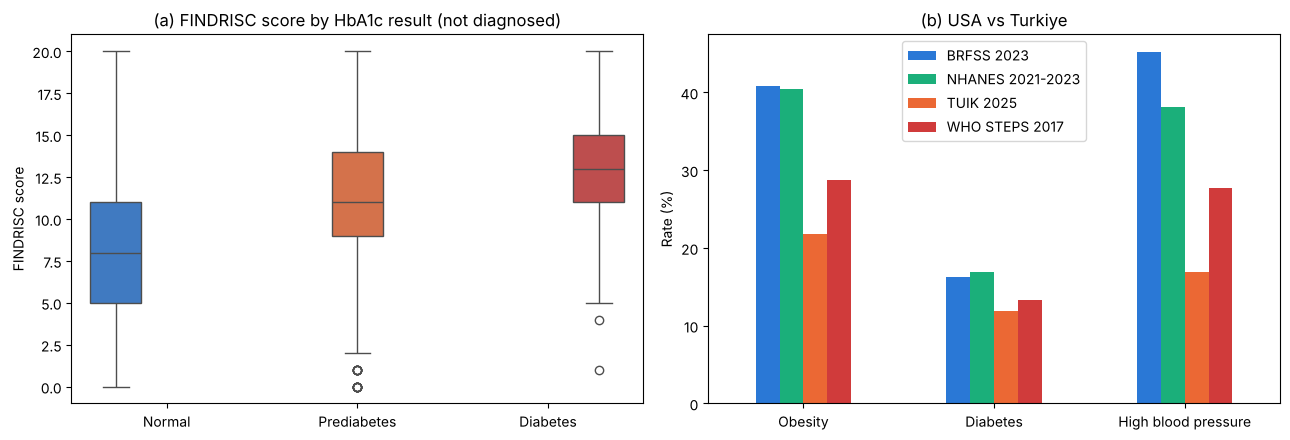

In [28]:
#FINDRISC AND TURKIYE GRAPHS
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.boxplot(data=nd, x="lab_group", y="findrisc", hue="lab_group", legend=False, ax=axes[0],
            palette=["#2a78d6", "#eb6834", "#d03b3b"])
axes[0].set_title("(a) FINDRISC score by HbA1c result (not diagnosed)")
axes[0].set_xlabel("")
axes[0].set_ylabel("FINDRISC score")

tab.plot(kind="bar", ax=axes[1], color=["#2a78d6", "#1baf7a", "#eb6834", "#d03b3b"], rot=0)
axes[1].set_title("(b) USA vs Turkiye")
axes[1].set_ylabel("Rate (%)")

plt.tight_layout()
plt.savefig("fig_findrisc_turkiye.png", dpi=200)
plt.show()

In [29]:
#SAVE CLEAN DATA
for y in ["2019", "2021", "2023"]:
    years[y].to_csv(f"brfss{y}_clean.csv", index=False)
nh.to_csv("nhanes_clean.csv", index=False)